# FlashAttention: Exact Attention with Less Memory Traffic

[Multi-query and grouped-query attention](attention_mechanisms.ipynb) change the **architecture**: how many key/value heads a model has. FlashAttention changes the **algorithm**: how $\operatorname{softmax}(QK^\top/\sqrt{d_k})\,V$ is computed on a GPU. The result is exactly the same attention, up to floating-point rounding. It is faster and needs far less memory because it never stores the `T × T` matrix of attention scores.

To see where each method helps, this notebook first separates the phases in which a language model runs attention: training, prompt prefill, and decoding.

**What you will learn**

1. How **prompt prefill** and **decoding** differ from each other and from training, and which bottleneck dominates each phase.
2. Why the `T × T` score matrix, not the arithmetic, is the problem in training and prefill.
3. How a GPU's two kinds of memory (large, slow **HBM** and small, fast on-chip **SRAM**) shape the cost of attention.
4. What a GPU **kernel** is, and how **kernel fusion** keeps intermediate results on-chip.
5. How the **online softmax** computes an exact softmax one block at a time, and how FlashAttention's tiled loop uses it.

**Prerequisites:** scaled dot-product attention, softmax, tensor shapes, and the KV cache. Read the [key–value cache](key_value_cache.ipynb) and [attention mechanisms](attention_mechanisms.ipynb) notebooks first: this notebook uses their decoding bottleneck (Section 2 of attention mechanisms) and their Llama-2-7B memory arithmetic.

**Setup:** PyTorch and matplotlib only. Everything runs on a CPU in a few seconds; no GPU is needed, because the notebook explains the GPU algorithm with small CPU examples rather than running a GPU kernel. The memory calculations use sizes from **Llama-2-7B** (32 layers, 32 heads, head width 128, fp16).

**Contents**

1. Training, prefill, and decode
2. Two memory problems
3. What problem FlashAttention solves
4. GPU kernels and kernel fusion
5. The online softmax
6. In practice: PyTorch, and how the methods combine
7. Summary
8. Check your understanding

In [ ]:
import math
import torch
import matplotlib.pyplot as plt

# Llama-2-7B-like sizes, fp16 (the same numbers as Section 6 of attention_mechanisms.ipynb)
N_LAYERS, H, DH, BYTES = 32, 32, 128, 2

def kv_cache_bytes(batch, seq_len, kv_heads, n_layers=N_LAYERS, head_dim=DH, bytes_per_value=BYTES):
    return 2 * batch * kv_heads * seq_len * head_dim * n_layers * bytes_per_value   # 2 = K and V

colors = ["#c0392b", "#2980b9"]   # MHA, GQA-8 (same colours as attention_mechanisms.ipynb)
print(f"torch {torch.__version__}")

## 1. Training, prefill, and decode

Generation happens in two phases, which the [key–value cache](key_value_cache.ipynb) notebook introduced: **prefill** and **decode**.

### Prefill vs. decode: the two phases of generation

Take the prompt `"The robot opened the"` (5 tokens) and ask the model to continue it.

**Phase 1: prefill (read the whole prompt at once).** All 5 prompt tokens are already known, so nothing has to be generated before they can be processed. The model runs **all 5 through the network in one forward pass**, in parallel, with the causal mask stopping each token from seeing later ones. This is the same computation as a training forward pass. That one pass does two things:

1. It **fills the KV cache**: every layer computes and stores K and V for all 5 tokens. The name "prefill" comes from this.
2. It **predicts the first new token**: the output at the last position gives the next word, for example "door".

Each head's score matrix is `Tq × Tk = 5 × 5`. With a 4,000-token prompt it is `4000 × 4000`: a lot of arithmetic, but all of it parallel.

**Phase 2: decode (one token per step).** Now the model generates "door", then "and", then "walked", and so on. Each token depends on the one before it, so these steps **cannot run in parallel**. At each step the model:

1. feeds in **only the newest token**;
2. computes that token's Q, K, and V, and appends its K and V to the cache;
3. lets its single query attend to **all cached keys**: the prompt plus everything generated so far;
4. predicts the next token, and repeats.

Each head's score matrix is a single row, `1 × Tk`.

```text
Prefill:  [The robot opened the]  --one parallel pass-->  cache = 5 tokens, predicts "door"
Decode:   [door]                  --one step-->           cache = 6 tokens, predicts "and"
          [and]                   --one step-->           cache = 7 tokens, predicts "walked"
          [walked]                --one step-->           cache = 8 tokens, ...
```

In a decode step the GPU does very little arithmetic, one query against the cache, but it still has to **read every cached K and V** from memory, in every layer. That is the memory-bound situation of Section 2 of [attention mechanisms](attention_mechanisms.ipynb).

### Training, prefill, and decode compared

Prefill is a training-style forward pass without the loss and the backward pass. Decode is the only phase that runs token by token, and it exists only at inference.

| | Training | Prompt prefill (inference) | Decode (inference) |
| --- | --- | --- | --- |
| Tokens processed per pass | whole sequence | whole prompt | **one** new token |
| Shape of the attention work | `Tq = Tk = T` | `Tq = Tk = T_prompt` | `Tq = 1`, `Tk = T` so far |
| Positions run in parallel? | yes | yes | **no**: one step after another |
| Causal mask | yes | yes | not needed: the cache holds only past tokens |
| Backward pass? | yes: loss on every position | no | no |
| KV cache | not used | **written** for the whole prompt | **read** in full, then one entry appended |
| Main bottleneck | arithmetic, plus the `T × T` score matrix in GPU memory (stored for the backward pass) | arithmetic, plus the `T × T` score matrix in GPU memory | **memory reads**: the whole KV cache, every step |
| What helps most | **FlashAttention** | **FlashAttention** | **MQA / GQA**, sliding windows (a smaller cache to read) |
| What the user notices | training time and cost | the wait before the first token appears | how fast tokens stream out |

So the two families of methods target different problems:

- **FlashAttention** removes the cost of storing the large `T × T` score matrix, which only exists when `Tq` is large: training and prefill.
- **MQA, GQA, and sliding windows** shrink the KV cache, which is read in full at **every** decode step.

## 2. Two memory problems

The chart compares the two quantities for Llama-2-7B sizes. The score matrix grows **quadratically** with sequence length, while the KV cache grows **linearly**.

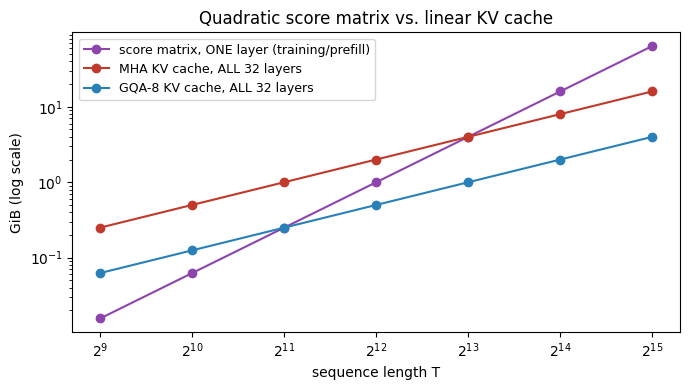

In [ ]:
seq_lens = [2**k for k in range(9, 16)]                            # 512 ... 32,768
score_matrix = [H * t * t * BYTES / 2**30 for t in seq_lens]      # one layer, B = 1, fp16
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(seq_lens, score_matrix, "o-", color="#8e44ad", label="score matrix, ONE layer (training/prefill)")
ax.plot(seq_lens, [kv_cache_bytes(1, t, 32) / 2**30 for t in seq_lens], "o-", color=colors[0], label="MHA KV cache, ALL 32 layers")
ax.plot(seq_lens, [kv_cache_bytes(1, t, 8) / 2**30 for t in seq_lens], "o-", color=colors[1], label="GQA-8 KV cache, ALL 32 layers")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("sequence length T"); ax.set_ylabel("GiB (log scale)")
ax.set_title("Quadratic score matrix vs. linear KV cache"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

- At `T = 32,768`, a **single layer's** score matrix (64 GiB) is larger than the whole model's MHA KV cache (16 GiB).
- FlashAttention never stores that matrix. Section 3 explains why that matters and how it is done.

## 3. What problem FlashAttention solves

FlashAttention solves a **memory-traffic problem**, not an arithmetic problem. Standard attention writes a huge intermediate matrix out to slow GPU memory and reads it back again. FlashAttention computes exactly the same result without ever storing that matrix.

**What standard attention does.** For one head with `T` tokens, $\operatorname{softmax}(QK^\top/\sqrt{d})\,V$ is usually computed in three separate steps:

```text
1. S = Q Kᵀ / √d                     write S (T, T) to GPU memory
2. P = softmax(S)       read S         write P (T, T)
3. O = P V              read P         write O (T, d)
```

A GPU has two kinds of memory. The figures below are for an A100, as given in Section 2.1 of the FlashAttention paper (Dao et al., 2022):

| | Size | Bandwidth |
| --- | --- | --- |
| **HBM** (high-bandwidth memory): the main GPU memory | 40–80 GB | about 1.5–2 TB/s |
| **SRAM**: on-chip memory next to the compute units | 192 KB per streaming multiprocessor × 108 (about 20 MB in total) | about 19 TB/s (estimated) |

The arithmetic happens on-chip, but `S` and `P` are far too large for SRAM. So each step writes its result to HBM, and the next step reads it back. This causes two problems:

1. **Memory size.** `S` and `P` grow as `T²`. That is the purple line in the chart above: at `T = 32,768`, the scores of a single layer take 64 GiB.
2. **Memory traffic.** Even when `S` and `P` fit, moving them in and out of HBM takes longer than the arithmetic itself, so the GPU mostly waits on memory. Training is worse, because `P` is also kept for the backward pass.

**What FlashAttention does.** It computes attention in **tiles** that fit in SRAM, and fuses all three steps into one GPU **kernel** (Section 4 explains kernels and fusion):

1. Load a block of `Q` and a block of `K` and `V` into SRAM.
2. Compute that block's scores, softmax weights, and weighted sum there.
3. Update running totals for the output with the **online softmax** (Section 5): a running maximum `m`, a running sum `l`, and an accumulator `acc`, rescaled whenever the maximum changes.
4. Discard the block's scores and move to the next block.

Only the final output `O`, of shape `(T, d)`, is written to HBM. The full `(T, T)` matrix never exists anywhere. For the backward pass, FlashAttention does not store `P`: it **recomputes** the tiles it needs from `Q`, `K`, and `V`. That costs extra arithmetic but saves more memory traffic, so the backward pass is still faster.

| | Standard attention | FlashAttention |
| --- | --- | --- |
| Result | exact | **the same**, up to floating-point rounding |
| Arithmetic (FLOPs) | grows as `T² · d` | about the same; slightly more in the backward pass |
| Extra memory | grows as `T²`, for `S` and `P` | grows as `T`: no `(T, T)` matrix |
| Reads and writes to HBM | large | much smaller, so it runs faster |

So FlashAttention does **not** make attention cheaper in arithmetic: its cost still grows as `T²`. What it removes is the storing and moving of the `(T, T)` matrix, which was the real bottleneck. The paper's title says this with the phrase **IO-aware**: the algorithm is designed around memory traffic (input/output), not FLOPs.

**Why it does not help decoding much.** During decoding `Tq = 1`, so the score "matrix" is a single row of `T` numbers, which is tiny. The cost there is reading the KV cache, and FlashAttention still has to read all of it. That is why the comparison table in Section 1 lists FlashAttention for training and prefill, and MQA/GQA for decoding.

## 4. GPU kernels and kernel fusion

A **kernel** is a function that runs on the GPU. The CPU starts ("launches") it, and the GPU runs it on thousands of threads at once, each working on a small piece of the data. Most PyTorch operations launch at least one kernel. A plain implementation of causal attention launches about five:

```python
S = Q @ K.transpose(-2, -1)                 # kernel 1: matrix multiply
S = S / math.sqrt(d)                        # kernel 2: scale
S = S.masked_fill(mask, float("-inf"))      # kernel 3: causal mask
P = S.softmax(dim=-1)                       # kernel 4: softmax
O = P @ V                                   # kernel 5: matrix multiply
```

Each kernel works the same way: it **reads** its inputs from HBM, computes on-chip, and **writes** its output back to HBM. Kernels do not share on-chip memory, so whatever one kernel held in SRAM is gone when it finishes, and the next kernel reads everything back from HBM. Here a `(T, T)` matrix is written to HBM four times and read back four times, even though each step does very little arithmetic per number.

**Kernel fusion** combines several operations into **one** kernel, so intermediate results stay on-chip instead of making round trips through HBM. An analogy: a kitchen where each cook does one step and then carries the dish to a walk-in fridge down the hall for the next cook to fetch, versus one cook doing every step at the counter and visiting the fridge only to fetch the ingredients and store the finished dish.

**The FlashAttention kernel** fuses all five steps (plus dropout during training) into a single kernel. The GPU's thread blocks share out the work, each taking a block of query rows. Each thread block loads its `Q` block into SRAM once, loops over blocks of `K` and `V` as described in Section 3, and writes only its rows of `O` to HBM.

| | Plain attention | FlashAttention |
| --- | --- | --- |
| Kernels launched | about 5 | 1 |
| `(T, T)` matrix in HBM | written and read back several times | never exists |
| Data moved through HBM | `Q`, `K`, `V`, `O`, plus the `(T, T)` matrices `S` and `P` several times | `Q` in once, `K` and `V` in once per query block, `O` out; nothing of size `(T, T)` |

The online softmax is what makes this fusion possible. An ordinary softmax needs a whole row of scores before it can start, so the kernel would have to wait for a complete `(T, T)` matrix. The online softmax works block by block, so the full row never has to exist.

Ordinary PyTorch operations cannot say "keep this in SRAM", so FlashAttention is written in low-level GPU code (CUDA; some versions use Triton). You rarely call it directly: Section 6 shows how PyTorch exposes it.

## 5. The online softmax: the trick that makes fusion possible

Softmax needs the maximum score and the sum over **all** keys, so how can it be computed block by block? The answer is to keep running totals and **rescale** them whenever a new block raises the maximum:

| Running value | Update for a new block of scores `s` |
| --- | --- |
| max `m` | `m_new = max(m, max(s))` |
| denominator `l` | `l = l · e^(m − m_new) + Σ e^(s − m_new)` |
| weighted values `acc` | `acc = acc · e^(m − m_new) + e^(s − m_new) · V_block` |

At the end, the output is `acc / l`, which is exactly equal to the full softmax result.

**Putting it together.** This is how the FlashAttention kernel uses these updates, in pseudocode:

```text
for each query block Q_i:                 # different query blocks run in parallel, one per thread block
    load Q_i from HBM into SRAM           # once
    m, l, acc = -inf, 0, 0                # kept on-chip
    for each K/V tile (K_j, V_j):
        load K_j, V_j from HBM into SRAM  # K and V re-read for every query block
        compute scores, update m, l, acc  # all on-chip, using the table above
        discard the tile's scores
    O_i = acc / l                         # normalise once
    write O_i to HBM                      # once, at the end
```

- `acc` is never written to HBM; only the finished, normalised `O_i` is.
- In training and prefill, `K` and `V` are the projections of the current sequence, read from HBM. They come from the KV cache only during decoding.

The cell below runs the **inner loop** for a single query vector and 12 keys, in blocks of 4.

In [ ]:
torch.manual_seed(0)
Tk, Dh_demo, block = 12, 4, 4
q, K_all, V_all = torch.randn(Dh_demo), torch.randn(Tk, Dh_demo), torch.randn(Tk, Dh_demo)
reference = (K_all @ q / math.sqrt(Dh_demo)).softmax(dim=0) @ V_all      # needs all Tk scores at once

m, l, acc = torch.tensor(float("-inf")), torch.tensor(0.0), torch.zeros(Dh_demo)
for start in range(0, Tk, block):
    s = K_all[start:start + block] @ q / math.sqrt(Dh_demo)              # this block's scores only
    m_new = torch.maximum(m, s.max())
    rescale = torch.exp(m - m_new)                                        # correct earlier totals for the new max
    p = torch.exp(s - m_new)
    l = l * rescale + p.sum()
    acc = acc * rescale + p @ V_all[start:start + block]
    m = m_new
    print(f"keys {start:>2}-{start + block - 1:>2}: running max = {m.item():.3f}, running sum = {l.item():.3f}")

print("\nblockwise result:", [f"{v:.4f}" for v in (acc / l).tolist()])
print("full softmax    :", [f"{v:.4f}" for v in reference.tolist()])
assert torch.allclose(acc / l, reference, atol=1e-6)

keys  0- 3: running max = 0.822, running sum = 1.488
keys  4- 7: running max = 0.822, running sum = 3.189
keys  8-11: running max = 2.221, running sum = 2.583

blockwise result: ['-0.7424', '-0.3443', '0.4895', '0.7883']
full softmax    : ['-0.7424', '-0.3443', '0.4895', '0.7883']


- At no point were all 12 scores held at once, yet the result is identical.
- FlashAttention applies the same idea to tiles of `Q`, `K`, and `V` on the GPU, and also recomputes the needed tiles during the backward pass instead of storing the full matrix.

## 6. In practice: PyTorch, and how the methods combine

PyTorch's `F.scaled_dot_product_attention` automatically dispatches to fused, FlashAttention-style kernels where the hardware supports them. From PyTorch 2.5 it also accepts `enable_gqa=True`, which shares K/V heads without the `repeat_interleave` copy used in [attention mechanisms](attention_mechanisms.ipynb) Section 4. Check the installed version before relying on that flag.

FlashAttention is one of three separate ideas that a modern LLM combines:

```text
MHA / GQA / MQA : which Q, K, V heads exist?               (architecture)
KV cache        : which old K, V tensors are reused?       (inference bookkeeping)
FlashAttention  : how is softmax(QKᵀ)V computed?           (kernel / algorithm)
```

A typical modern LLM uses all three: **GQA** in its architecture, a **KV cache** during generation, and a **FlashAttention** kernel for computing attention.

## 7. Summary

| Idea | What it is | Why it matters |
| --- | --- | --- |
| Training and prefill | all positions at once: `Tq = Tk = T` | bottleneck: arithmetic plus the `(T, T)` score matrix |
| Decode | one new token per step: `Tq = 1` | bottleneck: reading the whole KV cache every step |
| HBM vs. SRAM | large, slow main GPU memory vs. tiny, fast on-chip memory | moving data through HBM, not arithmetic, often limits attention |
| Kernel fusion | several operations in one GPU kernel | intermediate results stay on-chip |
| Online softmax | exact softmax computed block by block with running `m`, `l`, `acc` | makes fusion possible: the full row of scores never has to exist |
| FlashAttention | one fused, tiled attention kernel | same result; extra memory grows as `T`, not `T²`; much less HBM traffic |

**Common misconceptions**

- *"FlashAttention approximates attention."* No: it computes exactly the same result, up to floating-point rounding (Sections 3 and 5).
- *"FlashAttention makes attention linear in sequence length."* No: the arithmetic still grows as `T²`. The extra **memory** grows as `T`, because the `(T, T)` matrix is never stored (Section 3).
- *"FlashAttention speeds up decoding the most."* No: during decoding `Tq = 1`, the score row is tiny, and the cost is reading the KV cache. FlashAttention helps most in training and prefill (Section 1).
- *"FlashAttention writes the running output to memory after every block."* No: in the loop shown in Section 5, `m`, `l`, and `acc` stay on-chip, and each query block's `O_i = acc / l` is written once at the end.

## 8. Check your understanding

1. Why is prompt prefill "a training-style forward pass", and what does it skip?
2. FlashAttention helps most in which phase, training/prefill or decoding? Why?
3. In the plain five-kernel attention of Section 4, why does every kernel boundary cost a trip through HBM?
4. Why does an ordinary softmax prevent fusing the whole attention computation into one kernel?
5. In online softmax, why must `acc` and `l` be rescaled when the running maximum changes?
6. If the sequence length `T` doubles, roughly how do FlashAttention's arithmetic and its extra memory change?
7. In the FlashAttention loop of Section 5, which quantities stay on-chip, and which are written to HBM?

<details>
<summary><b>Show answers</b></summary>

1. Like training, prefill processes every prompt position in parallel in one forward pass with a causal mask. It skips the loss and the backward pass; instead it stores K and V in the cache and predicts the first new token.
2. Training and prefill: there `Tq = T`, so the `T × T` score matrix is large. During decoding `Tq = 1`, so the score row is tiny and the KV cache is the bottleneck.
3. Kernels do not share on-chip memory. When a kernel finishes, whatever it held in SRAM is gone, so it must write its output to HBM, and the next kernel must read it back.
4. An ordinary softmax needs the maximum and the sum over the whole row of scores before it can produce any weight, so the full row (and with it the `T × T` matrix) would have to exist first. The online softmax works block by block instead.
5. Earlier terms were computed as `e^(s − m_old)`. Multiplying by `e^(m_old − m_new)` converts them to `e^(s − m_new)`, so all terms share the same reference maximum.
6. The arithmetic grows about 4 times, because it scales with `T²`. The extra memory grows about 2 times, because it scales with `T`: only `O` and small per-row statistics are stored, never a `(T, T)` matrix.
7. On-chip: the current `Q` block, the current `K`/`V` tile, its scores, and the running `m`, `l`, and `acc`. Written to HBM: only the finished `O_i = acc / l` for each query block (in training, also a small per-row statistic for the backward pass).

</details>

## References

1. Dao et al., [FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness](https://arxiv.org/abs/2205.14135), 2022. (Section 2.1 gives the A100 memory figures used in Section 3.)
2. Dao, [FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning](https://arxiv.org/abs/2307.08691), 2023.
3. Milakov and Gimelshein, [Online normalizer calculation for softmax](https://arxiv.org/abs/1805.02867), 2018. (The online softmax.)
4. Vaswani et al., [Attention Is All You Need](https://arxiv.org/abs/1706.03762), 2017.
5. Touvron et al., [Llama 2: Open Foundation and Fine-Tuned Chat Models](https://arxiv.org/abs/2307.09288), 2023. (Model sizes used in the memory calculations.)
6. Course notebooks: [key–value cache](key_value_cache.ipynb) · [attention mechanisms: MHA, GQA, MQA](attention_mechanisms.ipynb).